# C. elegans Data processing

After downloading all datasets (as described in raw/celegans/readme.txt) we proceed to process the data. 

We need to build the adjacency matrices for each snapshot.

In [16]:
import pandas as pd
import warnings
import xlrd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

In [17]:
input_folder = "data/raw/celegans/"
output_folder = "data/processed/celegans/"

!mkdir -p data/processed/celegans/

### Adjacency matrices

We want to obtain the set of all neurons present in at least one snapshot of the connectome.

In [18]:
all_neurons = []
for n_dataset in range(1, 9):
    data = pd.read_csv(f"{input_folder}/witvliet_2020_{str(n_dataset)}.csv", header=0, delimiter="\t")
    data = data[data["type"]!="electrical"].reset_index()
    neurons = list(set(data["pre"].to_list() + data["post"].to_list()))
    all_neurons = list(set(all_neurons + neurons))

data.head()

,index,pre,post,type,synapses
0,2,ADAL,AVAL,chemical,2
1,3,ADAL,AVAR,chemical,1
2,4,ADAL,AVBL,chemical,16
3,5,ADAL,AVBR,chemical,6
4,7,ADAL,AVDR,chemical,1


In [19]:
print(f"N = {len(all_neurons)}")

N = 223


Now we want to build the adjacency matrices. $A^t_{ij}$ corresponds to the synaptic count from neuron $i$ to neuron $j$ at snapshot $t$. We store each snapshot independently in our output folder. Note that we sort neurons by names.

In [20]:
matrices = []
sorted_matrices = []

for n_dataset in range(1, 9):
    
    data = pd.read_csv(f"{input_folder}/witvliet_2020_{str(n_dataset)}.csv", header=0, delimiter="\t")
    data = data[data["type"]!="electrical"].reset_index() #only CHEMICAL synapses
    
    #adjacency matrix containing all possible neuron interactions filled with 0s:
    matrix_data = pd.DataFrame(columns=all_neurons, index=all_neurons).fillna(0)
    
    #fill with number of synapses
    for i in data.itertuples():
        matrix_data.loc[i.post, i.pre] = i.synapses 
        
    matrices.append(matrix_data)
    
    #sort alphabetically neurons (both indices and column names)
    matrix_data = matrix_data.reindex(sorted(matrix_data.columns), axis=1)
    matrix_data = matrix_data.sort_index()

    sorted_matrices.append(matrix_data)
    matrix_data.to_csv(f"{output_folder}/adjMat_{str(n_dataset)}.csv")

matrix_data.head()

,ADAL,ADAR,ADEL,ADER,ADFL,ADFR,ADLL,ADLR,AFDL,AFDR,...,URAVL,URAVR,URBL,URBR,URXL,URXR,URYDL,URYDR,URYVL,URYVR
ADAL,0,0,1,0,0,0,2,0,0,0,...,0,0,5,0,0,0,0,0,0,0
ADAR,0,0,0,1,0,0,0,0,0,0,...,0,0,0,3,0,0,0,0,0,0
ADEL,0,0,0,3,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
ADER,0,0,4,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ADFL,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


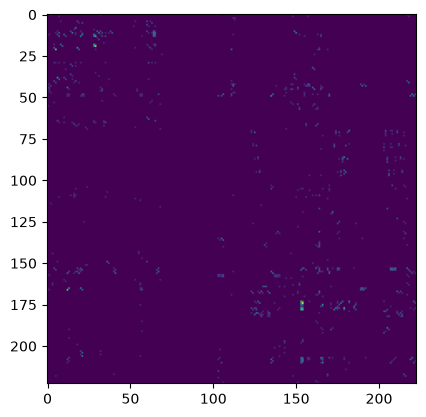

In [21]:
plt.imshow(sorted_matrices[0].to_numpy(dtype="int"))

### Groups and other neuron metadata

In [22]:
adjmat_neuron_names = np.array(matrix_data.columns)

We want to build a table in which we have the correspondence between neuron name, type and location.

In [23]:
data_neuron_type = pd.read_excel(f"{input_folder}/synapseNumberMatrix_suppl.xlsx", sheet_name='Dataset1', index_col=[0, 1], header=[0, 1])

# presynaptic neurons...
pre_names = data_neuron_type.iloc[0, 1:]  # first row, skip first column
pre_types = [col.split('.')[0] for col in data_neuron_type.iloc[:, 1:].columns.get_level_values(1)]
df_pre = pd.DataFrame({'name': pre_names, 'type': pre_types})

# postsynaptic neurons...
post_names = data_neuron_type.iloc[2:, 0].values  # skip first two rows
post_types = data_neuron_type.iloc[2:, :].index.get_level_values(1)
df_post = pd.DataFrame({'name': post_names, 'type': post_types})

# combine both dfs and take the same order of the neurons as we had in the adjacency matrices:
df_neurons = pd.concat([df_pre, df_post], ignore_index=True)
df_neurons = df_neurons.drop_duplicates(subset='name').sort_values('name').reset_index(drop=True)
df_neurons = df_neurons.set_index('name').loc[adjmat_neuron_names].reset_index()
df_neurons.head() 

ImportError: `Import openpyxl` failed.  Use pip or conda to install the openpyxl package.

In order to extract the location of each neuron, we must look at the neuron name. If the name is followed by an L or an R it means that it is a bilateral neuron (located in the Left or in the Right). The rest of the neurons lack a bilateral counterpart (we will use X for them) (wormatlas.org).

In [ ]:
patternR = pattern = r'\b\w*R\b|-\wR\w*'
patternL = pattern = r'\b\w*L\b|-\wL\w*'

location = []
for neuron_name in df_neurons["name"]:
    if pd.Series([neuron_name]).str.contains(patternR, regex=True).any():
        location.append("Right")
    elif pd.Series([neuron_name]).str.contains(patternL, regex=True).any():
        location.append("Left")
    else:
        location.append("Other") 
location = np.array(location)

df_neurons["location"] = location
df_neurons.head()

In [ ]:
print(f"Left: {np.sum(location == 'Left')}, Right: {np.sum(location == 'Right')}, X: {np.sum(location == 'Other')}")

In [ ]:
df_neurons.to_csv(f"{output_folder}/neuron_metadata.csv")

## Reduced version of the connectomes for the tutorial

In order to get a dataset with smaller networks, we will store the connectomes but just with the first 60 neurons each, so we can align them quickly.

In [ ]:
for n_dataset, mat in enumerate(sorted_matrices):
    mat.iloc[:60, :60].to_csv(f"{output_folder}/reduced_adjMat_{str(n_dataset)}.csv")

In [ ]:
df_neurons[:60].to_csv(f"{output_folder}/reduced_neuron_metadata.csv")